Targets: ['CO(GT)', 'C6H6(GT)', 'NOx(GT)', 'NO2(GT)']

=== Temporal Split (2004 → 2005) Results ===
Pollutant  Val_R2_2004tail  Val_MAE_2004tail  Test_R2_2005_RF  Test_MAE_2005_RF  Baseline_R2_2005  Baseline_MAE_2005  Train_n  Test_n
 C6H6(GT)         0.996756          0.062609         0.999610          0.044633          0.688914           2.163017     7086    2247
  NOx(GT)         0.809576         67.102625         0.957716         29.397471          0.731805          71.585684     7086    2247
   CO(GT)         0.894489          0.315133         0.949632          0.190579          0.683176           0.491948     7086    2247
  NO2(GT)         0.888745          9.735641         0.907700          9.965250          0.764671          18.317803     7086    2247


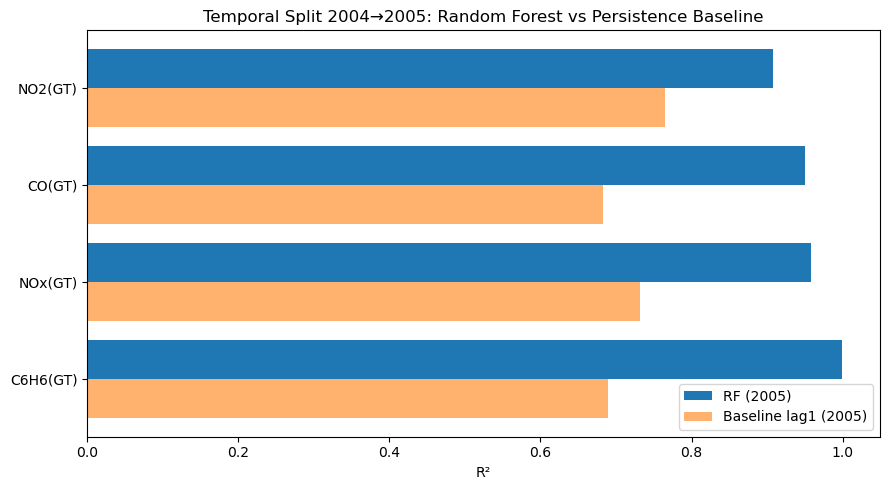

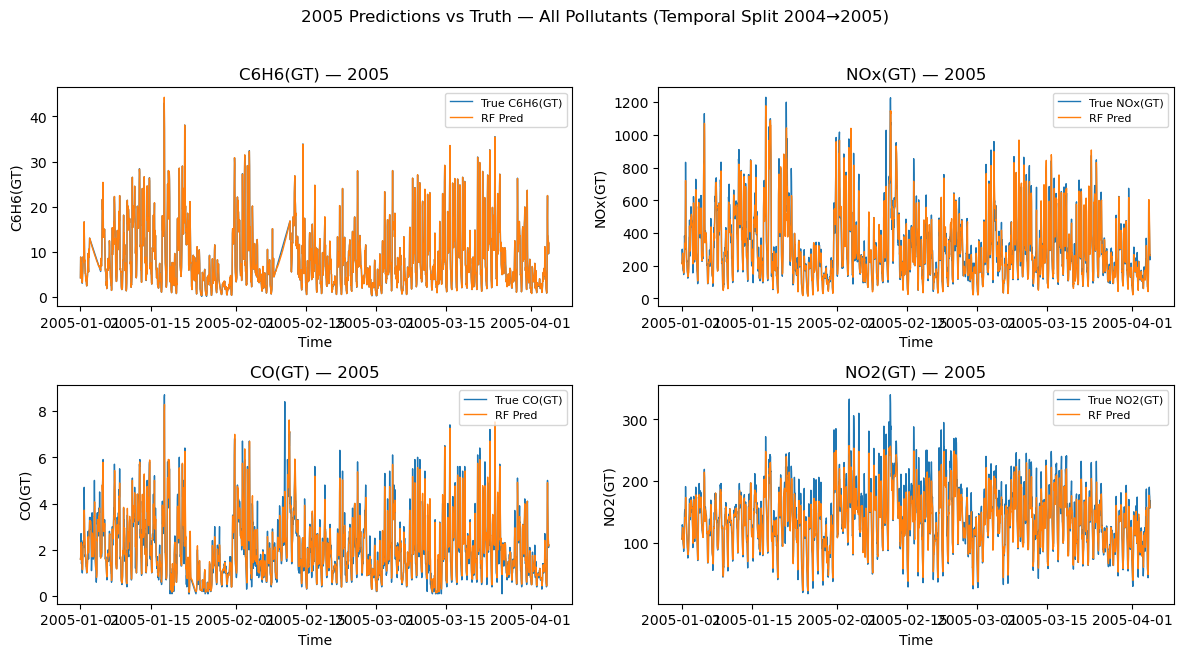


Summary:
- Chronological evaluation avoids leakage by training on 2004 and testing strictly on 2005.
- Validation uses the most recent 20% of 2004, simulating pre-deployment tuning.
- The lag-1 baseline provides a strict benchmark; RF should beat it if temporal features add value.


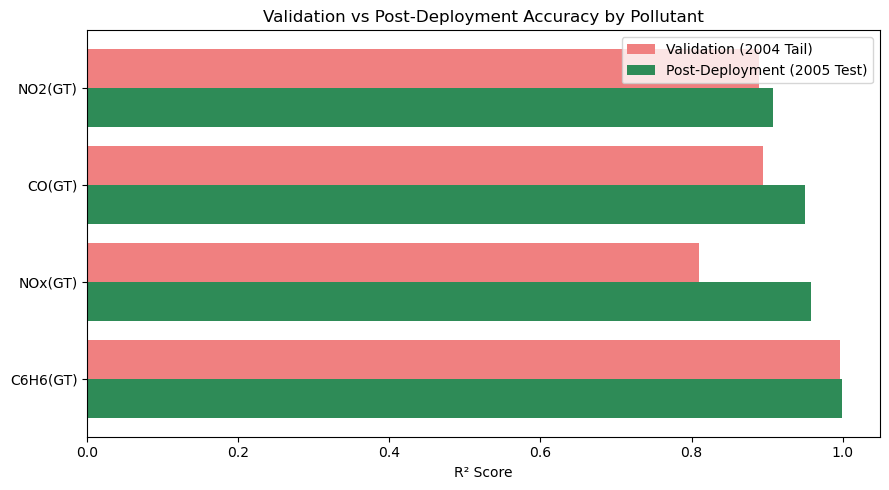


Interpretation:
• Validation R² (2004 tail) measures how well the model generalizes before deployment.
• Test R² (2005) reflects true post-deployment performance.
• The gap between them shows how temporal drift or changing conditions (traffic, weather) affect accuracy.
• Ideally, post-deployment R² should remain close to validation R² → indicating good robustness over time.


In [5]:
# =====================================================
# COMP9417 Air Quality Project
# STEP 6 — TEMPORAL DATA SPLITTING (Multi-Pollutant, 2004→2005)
# =====================================================
# Train on 2004, evaluate on 2005 for ALL (GT) pollutants.
# validation: last 20% of 2004.
# Compares Random Forest vs naïve persistence (lag-1).
# =====================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_absolute_error

# ---------- 1) Load cleaned hourly data ----------
df0 = pd.read_csv("AirQuality_clean.csv", parse_dates=["timestamp"]).sort_values("timestamp")
df0 = df0.set_index("timestamp")
# keep numeric copy to avoid accidental string columns later
df0 = df0.select_dtypes(include=[np.number]).copy()

# Identify ground-truth pollutant targets (e.g., CO(GT), NOx(GT), NO2(GT), C6H6(GT), etc.)
targets = [c for c in df0.columns if "(GT)" in c]
if not targets:
    raise ValueError("No '(GT)' pollutant columns found in AirQuality_clean.csv")

print("Targets:", targets)

# ---------- 2) Common time encodings ----------
df = df0.copy()
df["hour"]       = df.index.hour
df["weekday"]    = df.index.dayofweek
df["month"]      = df.index.month
df["is_weekend"] = df["weekday"].isin([5, 6]).astype(int)
# Cyclical encodings (help models learn wrap-around)
df["hour_sin"]   = np.sin(2*np.pi*df["hour"]/24);   df["hour_cos"]   = np.cos(2*np.pi*df["hour"]/24)
df["wday_sin"]   = np.sin(2*np.pi*df["weekday"]/7); df["wday_cos"]   = np.cos(2*np.pi*df["weekday"]/7)
df["month_sin"]  = np.sin(2*np.pi*df["month"]/12);  df["month_cos"]  = np.cos(2*np.pi*df["month"]/12)

# Helper: add target-specific temporal features
def add_temporal_features(data: pd.DataFrame, target: str,
                          lags=(1,3,6,12,24), rolls=(3,6,24)) -> pd.DataFrame:
    out = data.copy()
    for L in lags:
        out[f"{target}_lag{L}"] = out[target].shift(L)
    for W in rolls:
        out[f"{target}_rollmean{W}"] = out[target].rolling(W).mean()
        out[f"{target}_rollstd{W}"]  = out[target].rolling(W).std()
    return out


# ---------- 3) Train=2004, Test=2005 for each pollutant ----------
results = []
per_target_preds = {} 

for target in targets:
    data = df.copy()
    if target not in data.columns:
        print(f"Skipping {target}: not found after numeric filtering.")
        continue

    # add this target's lag/rolling features
    data = add_temporal_features(data, target)

    # drop rows made NaN by lag/rolling
    data = data.dropna()

    # chronological masks
    year = data.index.year
    train_mask = (year == 2004)
    test_mask  = (year == 2005)

    X_train_full = data.loc[train_mask].drop(columns=[]).copy()
    y_train_full = data.loc[train_mask, target].copy()
    X_test       = data.loc[test_mask].copy()
    y_test       = data.loc[test_mask, target].copy()

    # feature set = numeric-only (exclude the target)
    num_cols = X_train_full.select_dtypes(include=[np.number]).columns
    feat_cols = [c for c in num_cols if c != target]

    X_train_full = X_train_full[feat_cols]
    X_test       = X_test[feat_cols]

    # guardrails
    if len(X_train_full) == 0 or len(X_test) == 0:
        print(f"Skipping {target}: insufficient 2004/2005 coverage after feature generation.")
        continue

    # validation: last 20% of 2004
    val_frac = 0.20
    split_idx = int((1 - val_frac) * len(X_train_full))
    X_tr, X_val = X_train_full.iloc[:split_idx], X_train_full.iloc[split_idx:]
    y_tr, y_val = y_train_full.iloc[:split_idx], y_train_full.iloc[split_idx:]

    # model (simple RF; tune as needed)
    rf = RandomForestRegressor(n_estimators=200, random_state=42, n_jobs=-1)
    rf.fit(X_tr, y_tr)

    # validation metrics
    y_val_pred = rf.predict(X_val)
    r2_val  = r2_score(y_val, y_val_pred)
    mae_val = mean_absolute_error(y_val, y_val_pred)

    # refit on full 2004 before testing on 2005
    rf.fit(X_train_full, y_train_full)

    # test metrics (post-deployment)
    y_pred = rf.predict(X_test)
    r2_ts  = r2_score(y_test, y_pred)
    mae_ts = mean_absolute_error(y_test, y_pred)

    # baseline: persistence ŷ = lag1
    lag1_col = f"{target}_lag1"
    if lag1_col in data.columns:
        baseline = data.loc[test_mask, lag1_col].dropna()
        common_idx = baseline.index.intersection(y_test.index)
        base_r2  = r2_score(y_test.loc[common_idx], baseline.loc[common_idx])
        base_mae = mean_absolute_error(y_test.loc[common_idx], baseline.loc[common_idx])
    else:
        base_r2, base_mae = np.nan, np.nan

    results.append({
        "Pollutant": target,
        "Val_R2_2004tail": r2_val,
        "Val_MAE_2004tail": mae_val,
        "Test_R2_2005_RF": r2_ts,
        "Test_MAE_2005_RF": mae_ts,
        "Baseline_R2_2005": base_r2,
        "Baseline_MAE_2005": base_mae,
        "Train_n": len(X_train_full),
        "Test_n": len(X_test),
    })
    per_target_preds[target] = (y_test, pd.Series(y_pred, index=y_test.index))


# ---------- 4) Results table ----------
res_df = pd.DataFrame(results).sort_values("Test_R2_2005_RF", ascending=False)
print("\n=== Temporal Split (2004 → 2005) Results ===")
print(res_df.to_string(index=False))


# ---------- 5) Visualization: RF vs Baseline R² per pollutant ----------
if not res_df.empty:
    plt.figure(figsize=(9, 5))
    y_names = res_df["Pollutant"].values
    y_pos   = np.arange(len(y_names))
    plt.barh(y_pos + 0.2, res_df["Test_R2_2005_RF"].values, height=0.4, label="RF (2005)")
    plt.barh(y_pos - 0.2, res_df["Baseline_R2_2005"].values, height=0.4, label="Baseline lag1 (2005)", alpha=0.6)
    plt.yticks(y_pos, y_names)
    plt.xlabel("R²")
    plt.title("Temporal Split 2004→2005: Random Forest vs Persistence Baseline")
    plt.legend()
    plt.tight_layout()
    plt.show()


# ---------- 6) Show ALL pollutants' 2005 predictions vs truth ----------
import math

polls = list(per_target_preds.keys())
if not polls:
    raise ValueError("per_target_preds is empty — run the training loop above first.")

# order panels by best RF R² (descending), if res_df is available
try:
    order = res_df.sort_values("Test_R2_2005_RF", ascending=False)["Pollutant"].tolist()
    polls = [p for p in order if p in per_target_preds]
except Exception:
    pass  # fall back to whatever order we have

n = len(polls)
ncols = 2
nrows = math.ceil(n / ncols)

fig, axes = plt.subplots(nrows, ncols, figsize=(12, 3.2 * nrows), sharex=False)
axes = np.atleast_1d(axes).ravel()

for i, p in enumerate(polls):
    y_true, y_pred = per_target_preds[p]  # both are aligned by index
    ax = axes[i]
    ax.plot(y_true.index, y_true.values, label=f"True {p}", linewidth=1)
    ax.plot(y_pred.index, y_pred.values, label="RF Pred", linewidth=1)
    ax.set_title(f"{p} — 2005")
    ax.set_xlabel("Time")
    ax.set_ylabel(p)
    ax.legend(fontsize=8, loc="upper right")

# remove any unused axes
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

fig.suptitle("2005 Predictions vs Truth — All Pollutants (Temporal Split 2004→2005)", y=1.02, fontsize=12)
fig.tight_layout()
plt.show()

# ---------- 7) Summary text ----------
print("\nSummary:")
print("- Chronological evaluation avoids leakage by training on 2004 and testing strictly on 2005.")
print("- Validation uses the most recent 20% of 2004, simulating pre-deployment tuning.")
print("- The lag-1 baseline provides a strict benchmark; RF should beat it if temporal features add value.")

# ---------- 8) Validation vs Post-Deployment Accuracy Comparison ----------
if "Val_R2_2004tail" in res_df.columns:
    plt.figure(figsize=(9,5))
    y_names = res_df["Pollutant"].values
    y_pos = np.arange(len(y_names))

    plt.barh(y_pos + 0.2, res_df["Val_R2_2004tail"], height=0.4,
             color="lightcoral", label="Validation (2004 Tail)")
    plt.barh(y_pos - 0.2, res_df["Test_R2_2005_RF"], height=0.4,
             color="seagreen", label="Post-Deployment (2005 Test)")
    plt.yticks(y_pos, y_names)
    plt.xlabel("R² Score")
    plt.title("Validation vs Post-Deployment Accuracy by Pollutant")
    plt.legend()
    plt.tight_layout()
    plt.show()

# ---------- 9) Summary text ----------
print("\nInterpretation:")
print("• Validation R² (2004 tail) measures how well the model generalizes before deployment.")
print("• Test R² (2005) reflects true post-deployment performance.")
print("• The gap between them shows how temporal drift or changing conditions (traffic, weather) affect accuracy.")
print("• Ideally, post-deployment R² should remain close to validation R² → indicating good robustness over time.")

